In [70]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from src import Questions


plt.rcParams.update({'font.size': 14})

In [71]:
# creating a dataframe of all of the annotator profiles
EXCLUDED_SCORES = ["2_13", "23_", "24_", "25_", "27_"]
EXCLUDED_WHOLE = [23, 24, 25, 27]
ALL_MT = [2]
ALL_KNR = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 18, 19]
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)


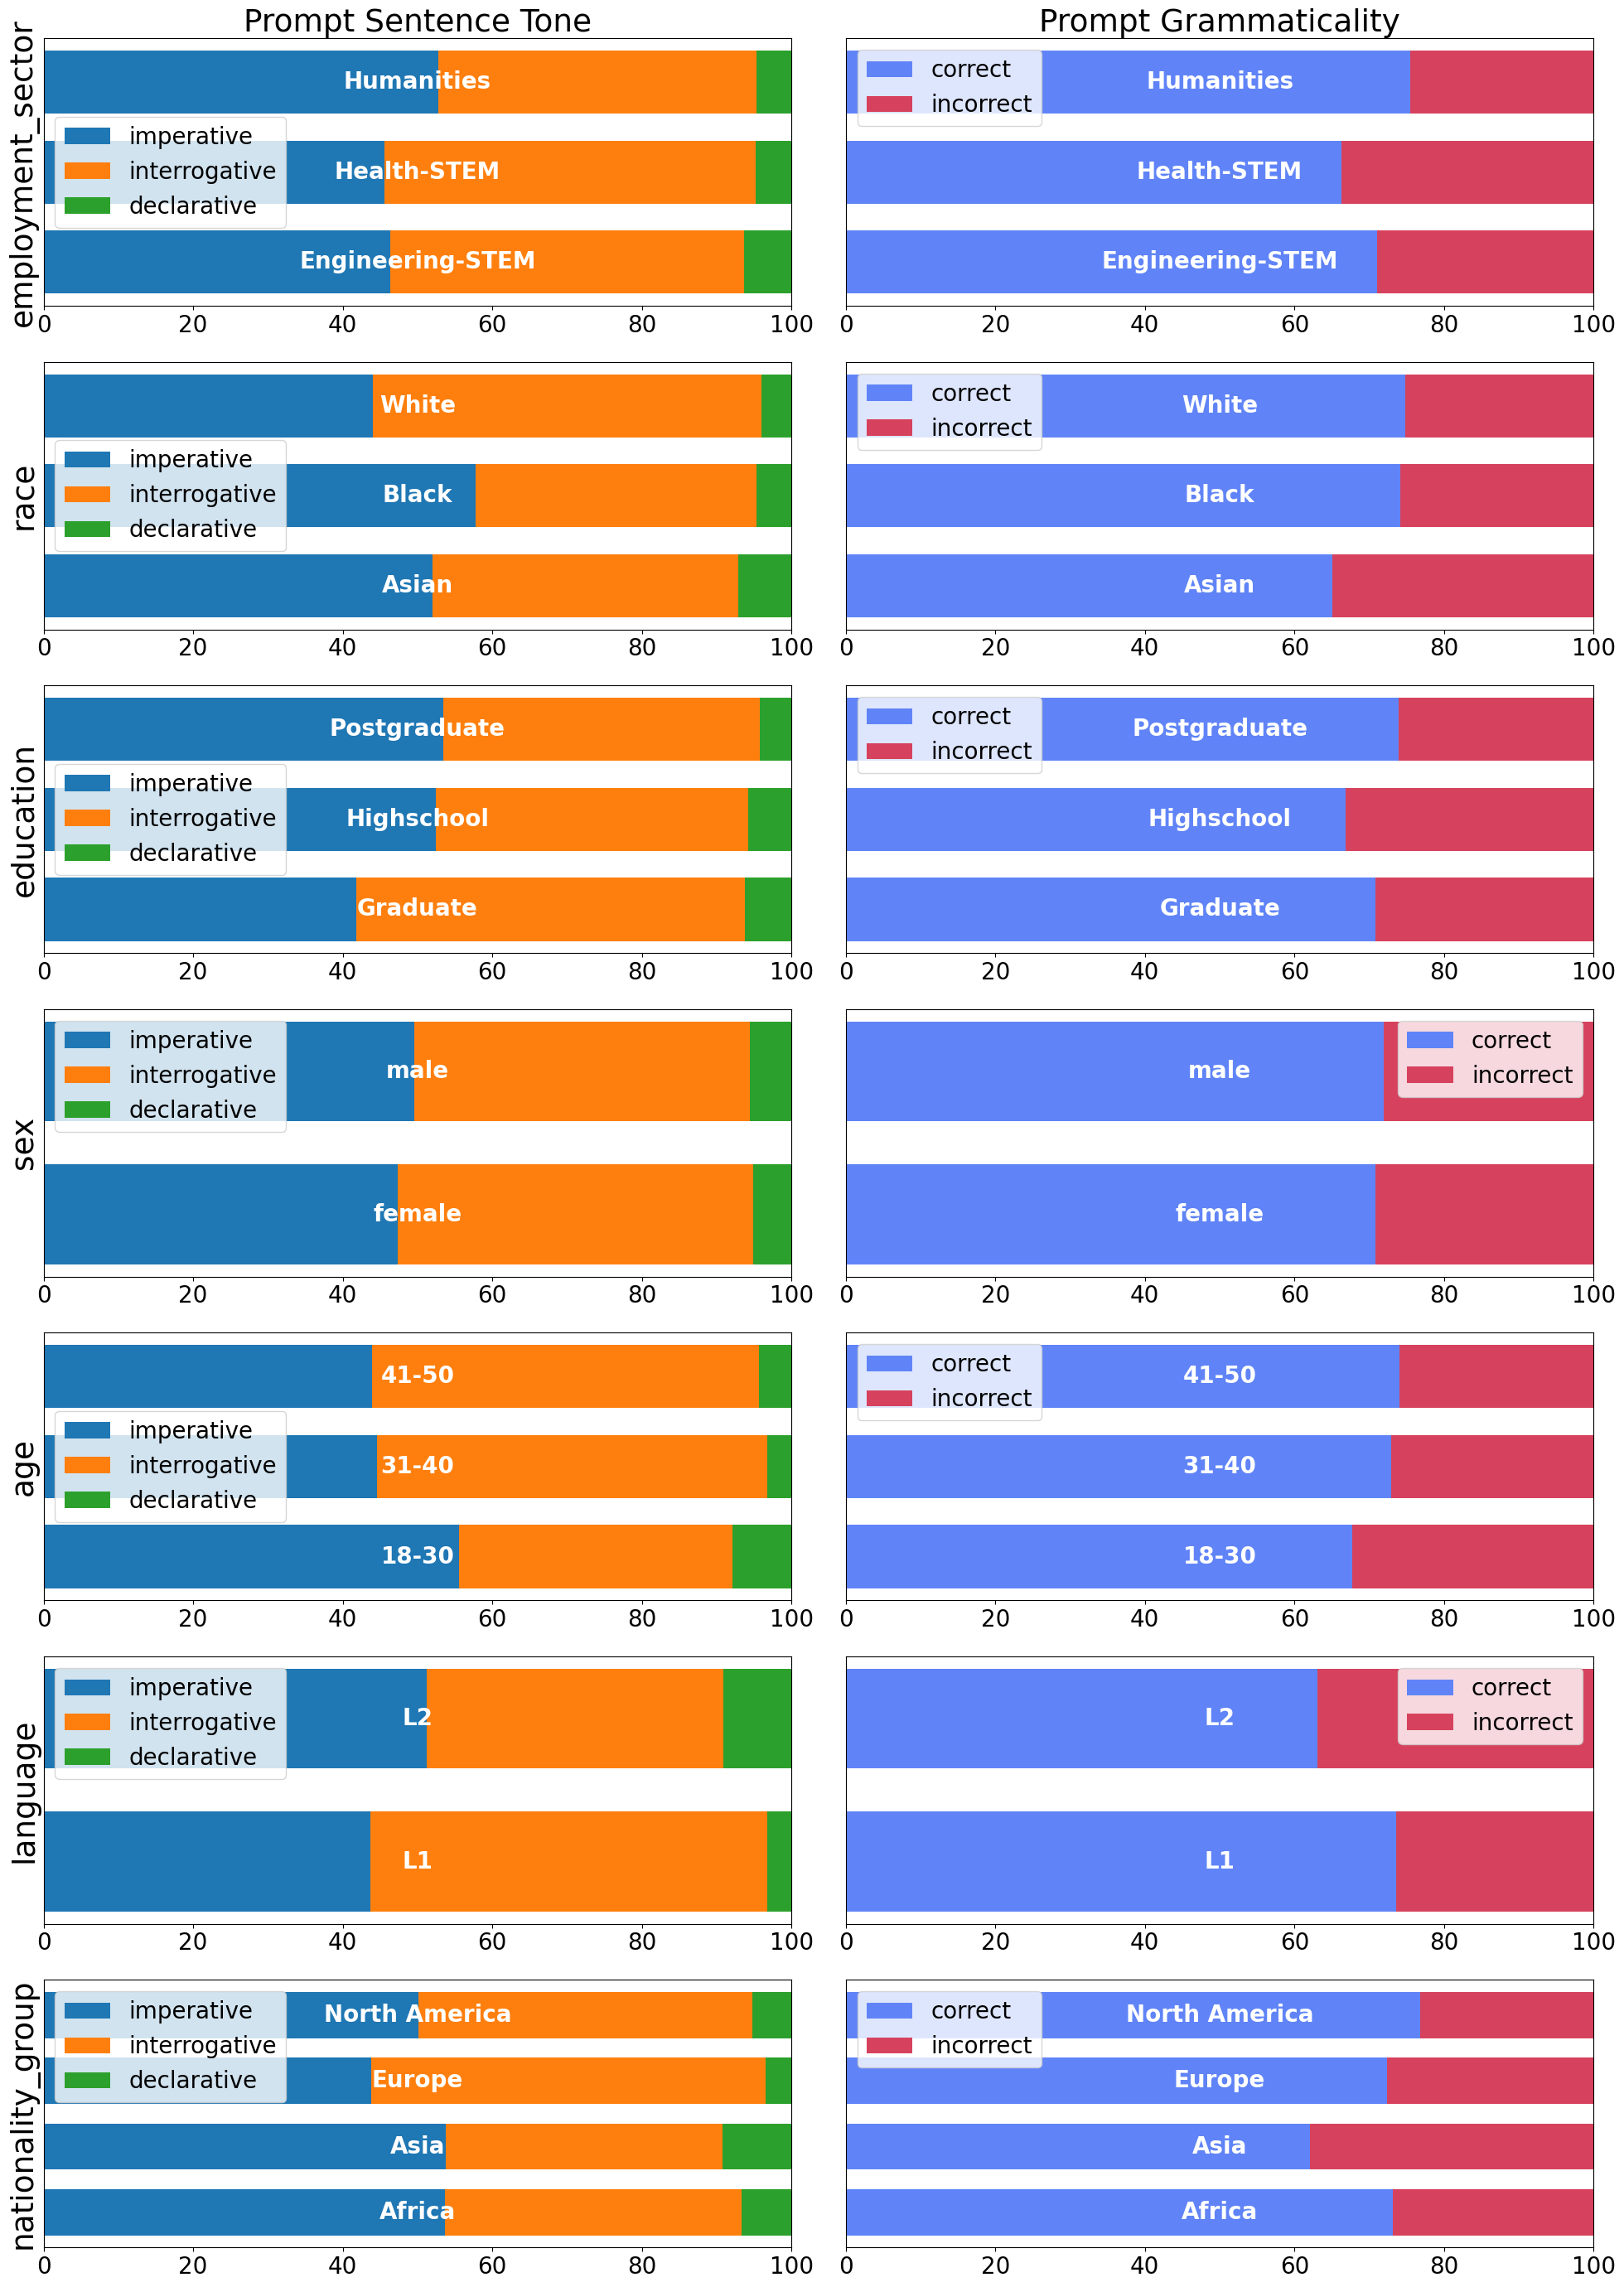

In [72]:
FONTSIZES=20
FS_EXT=7
plt.rcParams.update({'font.size': FONTSIZES})

def make_percent_category(data):
    result = {}
    for category, type_counts in data.items():
        total = sum(type_counts.values())
        result[category] = {k: (v / total * 100) for k, v in type_counts.items()} if total > 0 else {k: 0 for k in type_counts}
    return result

def plot_stacked_bar_chart(data, ax, height=0.5):
    """
    Horizontal stacked bar chart that writes each category label
    in the middle of the stacked bar.

    Args:
        data (dict): Nested dict with structure {category: {type: count}}.
        ax (matplotlib.axes.Axes): The Axes object to draw on.
        height (float): Height of each bar.
    """
    data = make_percent_category(data)
    categories = list(data.keys())
    types = list(next(iter(data.values())).keys())
    y = np.arange(len(categories))

    colors = ['#6084f7', '#d6425d'] if len(types) == 2 else None
    lefts = [0] * len(categories)

    for i, t in enumerate(types):
        values = [data[cat][t] for cat in categories]
        ax.barh(y, values, left=lefts, height=height,
                label=t, color=colors[i] if colors else None)
        lefts = [l + v for l, v in zip(lefts, values)]

    # --- label in the middle of each bar -------------------------------------
    for idx, cat in enumerate(categories):
        total = sum(data[cat].values())
        ax.text(total / 2, idx, cat,
                va='center', ha='center',
                color='white', weight='bold')

    # remove the default y-ticks/labels
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_xlim(0,100)
    ax.legend()

# making a df that has info: sum sentence length, freq count for each of the annotators
df_ptype_freqtable = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    prompt_lengths = []
    prompt_tone_freq_table = {
        "imperative" : 0,
        "interrogative" : 0,
        "declarative" : 0,
    }
    prompt_grammar_freq_table = {
        "correct" : 0,
        "incorrect" : 0,
    }
    
    for i, (question, v) in enumerate(annotator_object["answers"].items()):
        # # ALL
        # if i not in EXCLUDED_WHOLE :
        #     if v["answer"]:
        #         prompt_lengths.append(v["sentence_length"])
        #         prompt_tone_freq_table[v["sentence_type"]] += 1
        #         prompt_grammar_freq_table[v["grammaticality"]] += 1
        
        # # MT
        # if i in ALL_MT:
        #     if v["answer"]:
        #         prompt_lengths.append(v["sentence_length"])
        #         prompt_tone_freq_table[v["sentence_type"]] += 1
        #         prompt_grammar_freq_table[v["grammaticality"]] += 1
        
        # KNR
        if i in ALL_KNR:
            if v["answer"]:
                prompt_lengths.append(v["sentence_length"])
                prompt_tone_freq_table[v["sentence_type"]] += 1
                prompt_grammar_freq_table[v["grammaticality"]] += 1

    df_ptype_freqtable.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        "sum_prompt_lengths" : sum(prompt_lengths),
        **prompt_tone_freq_table,
        **prompt_grammar_freq_table
    })

df_ptype_freqtable = sorted(df_ptype_freqtable, key=lambda x: x["id"])
df_ptype_freqtable = pd.DataFrame(df_ptype_freqtable)


aggregates = {}
PROFILE_COLUMNS = ["employment_sector", "race", "education", "sex", "age", "language", "nationality_group"]
for pc in PROFILE_COLUMNS:
    aggregates[pc] = {}
    for demo_label_name, group_df in df_ptype_freqtable.groupby(pc):
        # implementing exceptions
        if pc == "employment_sector":
            group = group_df[group_df["language"] == "L1"]
        elif pc == "education":
            group = group_df[group_df["language"] == "L1"]
        elif pc == "sex":
            group = group_df[group_df["language"] == "L1"]
            
        elif(demo_label_name == "Black"):
            group = group_df[group_df["language"] == "L1"]
        elif(demo_label_name == "White"):
            group = group_df[group_df["language"] == "L1"]
        # implementing exceptions
        demo_label_plengths = group_df["sum_prompt_lengths"].to_list()
        
        tone_ftable = group_df[['imperative', 'interrogative', 'declarative']]
        tone_sums = tone_ftable.sum().to_dict()

        grammar_ftable = group_df[['correct', 'incorrect']]
        grammar_sums = grammar_ftable.sum().to_dict()

        group_stats = {
            "Prompt Lengths" : demo_label_plengths,
            "Prompt Tone" : tone_sums,
            "Prompt Grammar" : grammar_sums,
        }

        aggregates[pc][demo_label_name] = group_stats
# # visualizing
N = len(PROFILE_COLUMNS)
fig, axes = plt.subplots(N, 2, figsize=(20, 4 * N))



# Column labels
# column_labels = ['Sentence Length Histogram', 'Prompt Sentence Tone', 'Prompt Grammaticality']
column_labels = ['Prompt Sentence Tone', 'Prompt Grammaticality']
for col, label in enumerate(column_labels):
    axes[0, col].set_title(label, fontsize = FONTSIZES + FS_EXT)

# Row labels
for row, label in enumerate(PROFILE_COLUMNS):
    axes[row, 0].set_ylabel(label, rotation=90, fontsize = FONTSIZES + FS_EXT)

nrows, ncols = axes.shape
for i, j in np.ndindex(nrows, ncols):
    ax = axes[i, j]
    demo_profile = PROFILE_COLUMNS[i]
    demo_data = aggregates[demo_profile]
    # if j == 0:
    #     data = {k : v["Prompt Lengths"] for k, v in demo_data.items()}
    #     plot_histogram_by_category(data, ax)
    if j == 0:
        data = {k : v["Prompt Tone"] for k, v in demo_data.items()}
        plot_stacked_bar_chart(data, ax, height=0.7)
    else:
        data = {k : v["Prompt Grammar"] for k, v in demo_data.items()}
        plot_stacked_bar_chart(data, ax, height=0.7)

plt.tight_layout()
plt.show()

In [73]:
included_models = [
    "gpt_4o",
    "llama31_70b_Inst",
    "llama31_8B_Inst",
    "llama32_1B_Inst",
    "qwen25_72b_Inst",
    "Qwen25_7B_Inst",
    "Qwen25_1dot5B_Inst"
]

def transpose_dict(dict_input):
    swapped = {}
    for outer_key, inner_dict in dict_input.items():
        for inner_key, value in inner_dict.items():
            swapped.setdefault(inner_key, {})[outer_key] = value
    return swapped

def sort_dict_by_keys(d):
    return dict(sorted(d.items()))

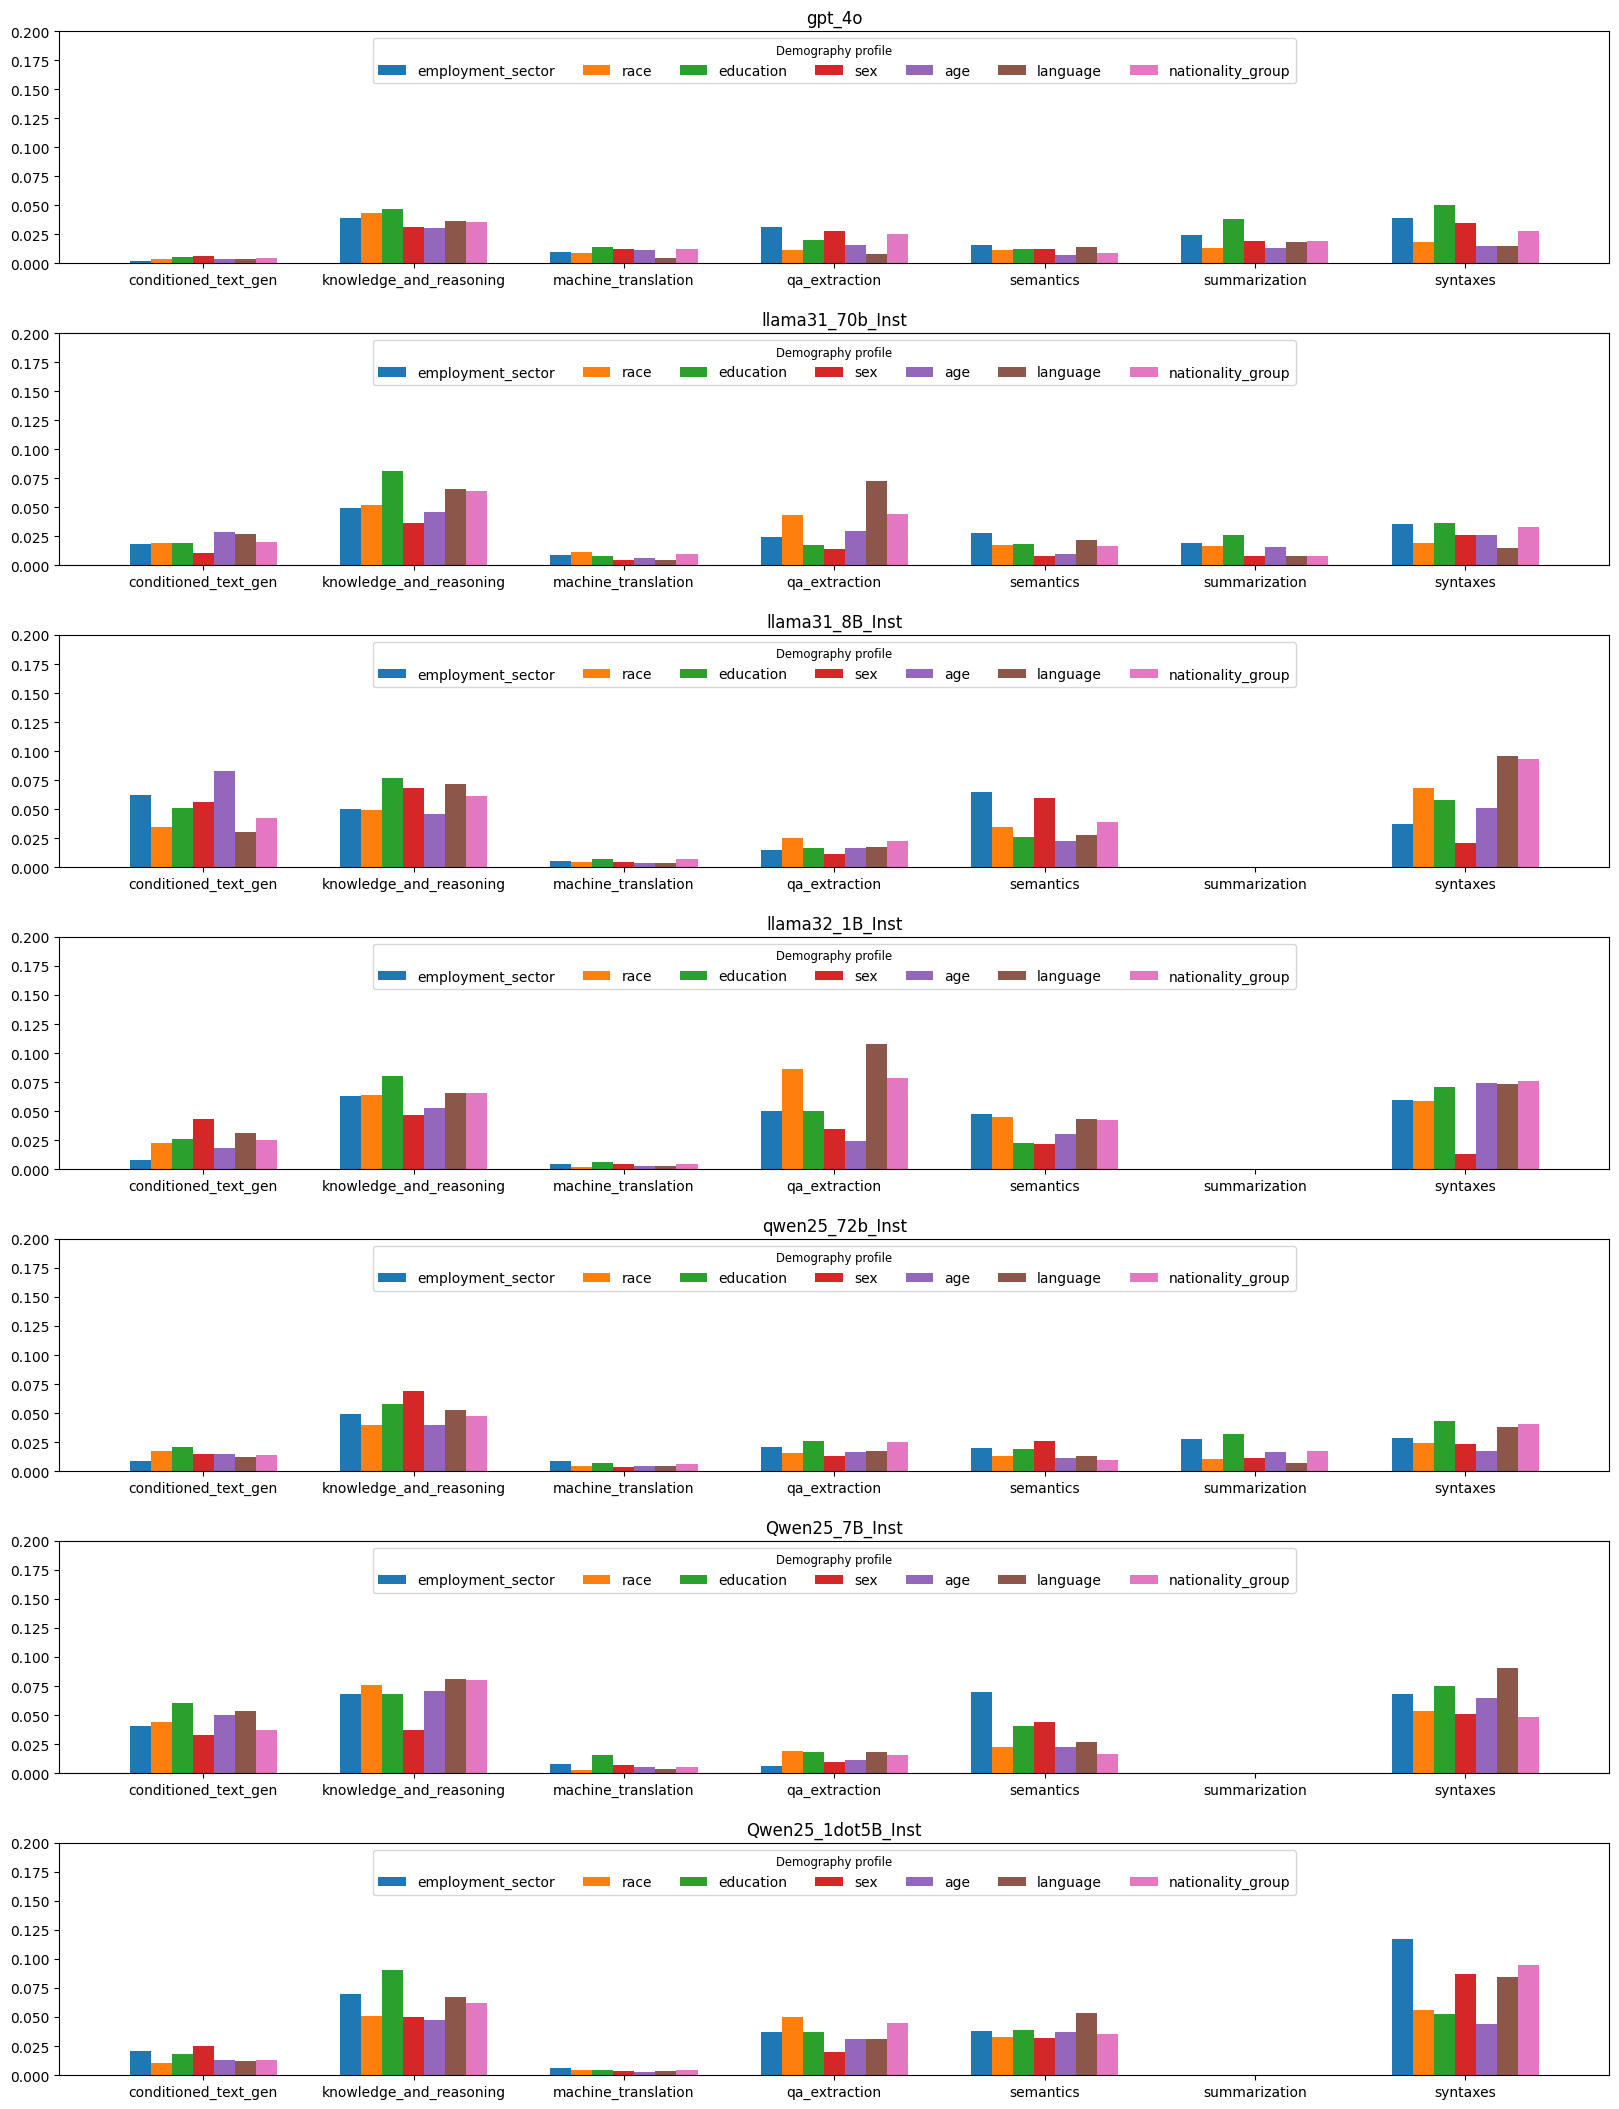

In [74]:
plt.rcParams.update(plt.rcParamsDefault)

from matplotlib.ticker import PercentFormatter
import numpy as np


divscores_path="score_tables/divscores"
gap_score_result_files = os.listdir(divscores_path)

data_full = {}
for model in included_models:
    data_full[model] = {}
    for tg_file in gap_score_result_files:
        if "model_v_taskg.csv" in tg_file:
            continue
        task_group = tg_file.replace("divscores_","").replace("ptt_","").replace(".csv","")
        df_asjs = json.loads(pd.read_csv(f"{divscores_path}/{tg_file}", index_col=0).set_index('model').to_json(orient='index'))
        data_full[model][task_group] = df_asjs[model]

# sort keys in each model's data
data_full = {model : sort_dict_by_keys(data_full[model]) for model in data_full}

bar_width = 0.1
fig, axes = plt.subplots(len(included_models), 1, figsize=(20, 4 * len(included_models)))
for i, ax in enumerate(axes):
    model_data = transpose_dict(data_full[included_models[i]])
    for j, (demo_profile, topics) in enumerate(model_data.items()):
        x = np.arange(len(topics))
        
        # as is
        ax.bar(x + j*bar_width, topics.values(), width=bar_width, label=demo_profile)
        
        # percentage
        # ax.bar(x + j*bar_width, [vv * 100 for vv in topics.values()], width=bar_width, label=demo_profile)

    # print(list(topics.keys()))
    ax.set_xticks(x + bar_width*(len(model_data)-1)/2)
    ax.set_xticklabels(list(topics.keys()), fontsize=10)
    ax.legend(title="Demography profile", ncol=7, loc='upper center', title_fontsize='small')
    ax.set_title(included_models[i])
    ax.set_ylim(0,0.2)
    # ax.set_ylim(0,110)
    # ax.yaxis.set_major_formatter(PercentFormatter())
fig.subplots_adjust(hspace=0.3, bottom=0.15)
plt.show()

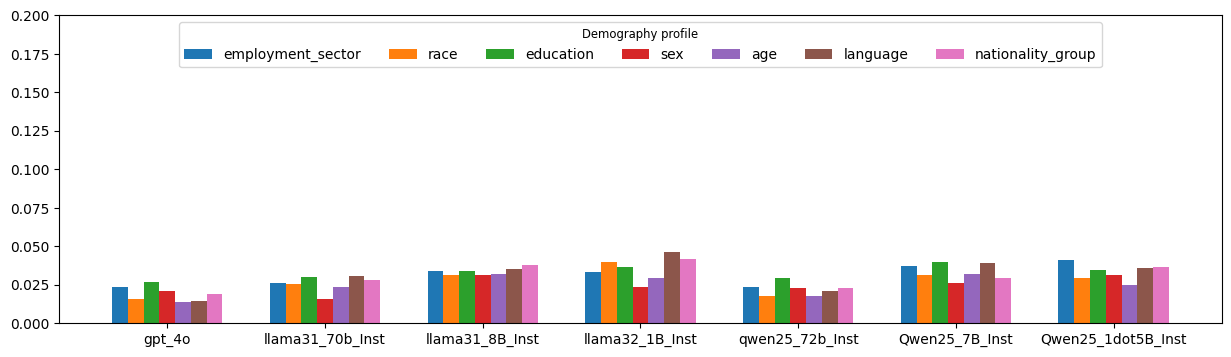

In [75]:
plt.rcParams.update(plt.rcParamsDefault)

import matplotlib.ticker as mtick

# aggregated_results
dirdir="divscores"
if dirdir == "divscores":
    scores_path=f"score_tables/{dirdir}"
else:
    scores_path=f"score_tables/{dirdir}/rawstr"
score_result_files = os.listdir(scores_path)

def aggregate_avg_all_data(all_data):
    """
    all data dict, just print all data to know what is expected by this function
    """
    all_data_agg = {}
    for modelname, values_to_agg in all_data.items():
        agg_obj = {}
        for task_group, tg_data in values_to_agg.items():
            # initializing the aggregate_object
            if not agg_obj:
                for k in tg_data.keys():
                    agg_obj[k] = []
            for k in tg_data.keys():
                agg_obj[k].append(tg_data[k])
        
        for aok, aov in agg_obj.items():
            agg_obj[aok] = sum(aov)/len(aov)
        all_data_agg[modelname] = agg_obj
    return all_data_agg

def aggregate_union_all_data(all_data):
    """
    ambatukms
    """
    all_data_agg = {}
    for modelname, values_to_agg in all_data.items():
        agg_obj = {}
        for task_group, tg_data in values_to_agg.items():
            if not agg_obj:
                for k in tg_data.keys():
                    agg_obj[k] = {
                        "rejectable" : [],
                        "all_tasks" : [],
                    }
            
            for k in tg_data.keys():
                tg_data_demop_obj = json.loads(tg_data[k])
                agg_obj[k]["rejectable"] += tg_data_demop_obj["rejectable"]
                agg_obj[k]["all_tasks"] += tg_data_demop_obj["all_tasks"]

        for aok, aov in agg_obj.items():
            agg_obj[aok] = len(aov["rejectable"])/len(aov["all_tasks"])
        all_data_agg[modelname] = agg_obj
    return all_data_agg

data_full = {}
for model in included_models:
    data_full[model] = {}
    for tg_file in score_result_files:
        if "model_v_taskg.csv" in tg_file:
            continue
        task_group = tg_file.replace("divscores_","").replace("ptt_","").replace(".csv","").replace("_rawstr","")
        df_asjs = json.loads(pd.read_csv(f"{scores_path}/{tg_file}", index_col=0).set_index('model').to_json(orient='index'))
        data_full[model][task_group] = df_asjs[model]

if dirdir == "divscores":
    data_full_agg = aggregate_avg_all_data(data_full)
else:
    data_full_agg = aggregate_union_all_data(data_full)

data_full_agg = transpose_dict(data_full_agg)

bar_width = 0.1
plt.figure(figsize=(15, 4))
for i, (demo_profile, per_model_data) in enumerate(data_full_agg.items()):
    assert list(per_model_data.keys()) == included_models
    x = np.arange(len(per_model_data))
    if dirdir == "divscores":
        plt.bar(x + i*bar_width, per_model_data.values(), width=bar_width, label=demo_profile)
    else:
        plt.bar(x + i*bar_width, [v * 100 for v in per_model_data.values()], width=bar_width, label=demo_profile)
if dirdir == "divscores":
    plt.ylim(0,0.2)
else:
    plt.ylim(0, 100)
    plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter())

plt.xticks(x + bar_width*(len(data_full_agg)-1)/2, included_models)
plt.legend(title="Demography profile", ncol=7, loc='upper center', title_fontsize='small')
plt.show()

In [60]:
print(json.dumps(model_data, indent=4))

{
    "employment_sector": {
        "conditioned_text_gen": 0.0540271132,
        "knowledge_and_reasoning": 0.0754707387,
        "machine_translation": 0.0763882264,
        "qa_extraction": 0.0837736943,
        "semantics": 0.1000851268,
        "summarization": 0.0224143524,
        "syntaxes": 0.1496615069
    },
    "race": {
        "conditioned_text_gen": 0.0281765019,
        "knowledge_and_reasoning": 0.0495824946,
        "machine_translation": 0.0546687626,
        "qa_extraction": 0.0893997671,
        "semantics": 0.0666588242,
        "summarization": 0.0118424625,
        "syntaxes": 0.0752914793
    },
    "education": {
        "conditioned_text_gen": 0.0469635628,
        "knowledge_and_reasoning": 0.0540030317,
        "machine_translation": 0.0720560963,
        "qa_extraction": 0.0672967933,
        "semantics": 0.0965378371,
        "summarization": 0.0558518222,
        "syntaxes": 0.0870336937
    },
    "sex": {
        "conditioned_text_gen": 0.064628483,
 

In [61]:
print(json.dumps(data["llama31_70b_Inst"], indent=4))

KeyError: 'llama31_70b_Inst'

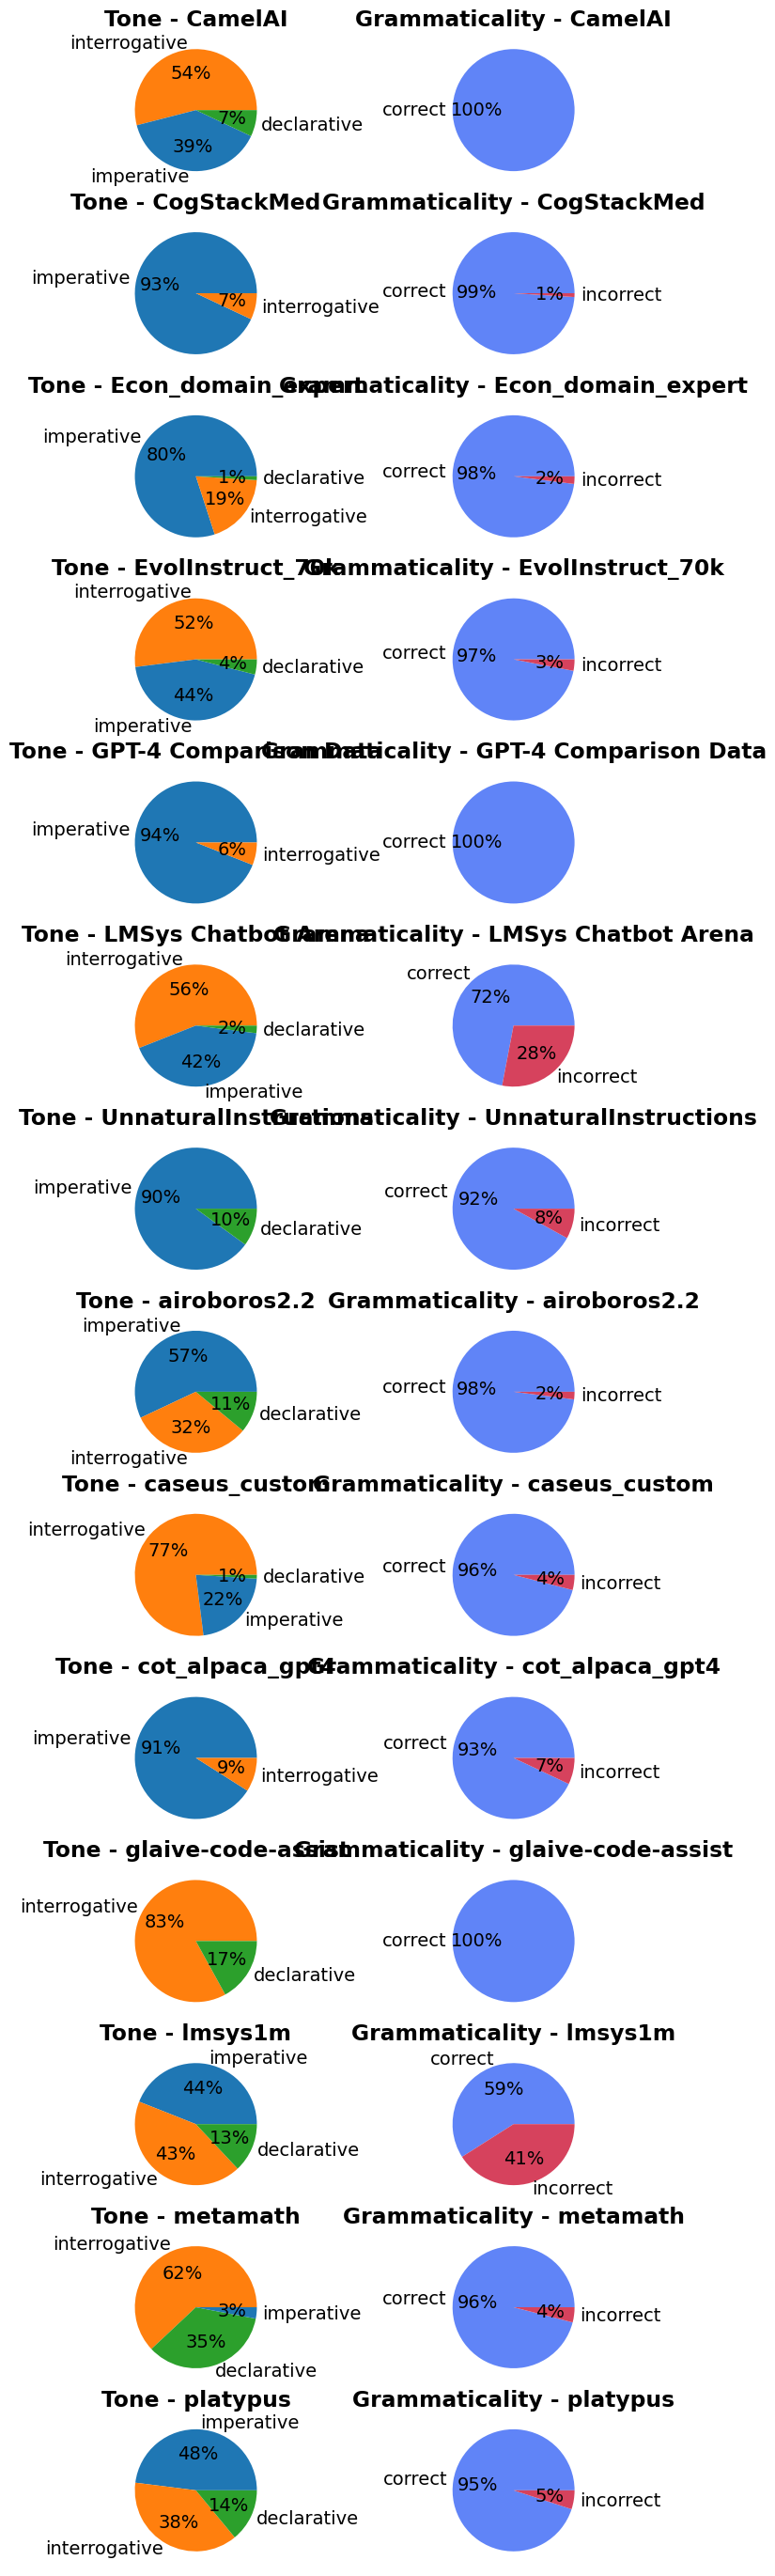

In [ ]:
import json
import pandas as pd

INST_TUNING_CLASSIF_DS = "inst_tuning_analysis/openhermes2_5_sample.csv"
INST_TUNING_CLASSIF_HISTORY = "inst_tuning_analysis/inst_tuning_analysis/history-inst_tuning_analysis.json"
history_file = json.load(open(INST_TUNING_CLASSIF_HISTORY, "r"))

public_inst_df = pd.read_csv(INST_TUNING_CLASSIF_DS)[["source", "instruction"]]

tone_answers = []
for msg in history_file['tone_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    tone_answers.append(answer)


grammar_answer = []
for msg in history_file['grammar_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    grammar_answer.append(answer)

public_inst_df['tone'] = tone_answers
public_inst_df['grammaticality'] = grammar_answer

full_data = {}
for groupname, group in public_inst_df.groupby("source"):
    full_data[groupname] = {
        "tone" : group['tone'].value_counts().to_dict(),
        "grammaticality" : group['grammaticality'].value_counts().to_dict(),
    }


color_dict = {
    "imperative" : "#1f77b4",
    "interrogative" : "#ff7f0e",
    "declarative" : "#2ca02c",
    "correct" : "#6084f7",
    "incorrect" : "#d6425d",
}

#  Sort keys to make consistent grid layout
keys = sorted(full_data.keys())
n = len(keys)

fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(8, n * 2.5))

for i, key in enumerate(keys):
    d = full_data[key]
    # Tones (left column)
    tone_ax = axes[i][0]
    tone_data = d['tone']
    tone_labels = list(tone_data.keys())
    tone_values = list(tone_data.values())
    tone_colors_used = [color_dict[label] for label in tone_labels]
    tone_ax.pie(tone_data.values(), labels=tone_data.keys(), autopct='%1.0f%%', colors=tone_colors_used)
    tone_ax.set_title(f'Tone - {key}', fontweight="bold")

    # Grammar (right column)
    grammar_ax = axes[i][1]
    grammar_data = d['grammaticality']
    grammar_labels = list(grammar_data.keys())
    grammar_values = list(grammar_data.values())
    grammar_colors_used = [color_dict[label] for label in grammar_labels]
    grammar_ax.pie(grammar_data.values(), labels=grammar_data.keys(), autopct='%1.0f%%', colors=grammar_colors_used)
    grammar_ax.set_title(f'Grammaticality - {key}', fontweight="bold")

plt.show()
